# CellVOCAL analysis of spatial mouse embryogenesis

This tutorial applies CellVOCAL to one prepared SPTEdU-seq embryo section. The model jointly learns RNA velocity and spatial communication influence using a common LR prior shared across developmental stages. Change `SAMPLE` to analyze another prepared section.

> Start Jupyter from the repository root. Training is commented by default.

**Required files.** Place prepared inputs under `paper/data/mouse_embryo/raw/`
and fitted H5AD files and checkpoints under `paper/data/mouse_embryo/cellvocal/`.
The shared LR table at `paper/data/mouse_embryo/lr_hits/lr_hits.csv` is not
bundled. To inspect saved fits without this table, comment out the
`lr_table = ...` and `lr_pairs = ...` lines in the configuration cell and keep
training commented out. The analysis cells use the fitted H5AD files and
checkpoints directly.

To train with the same common prior as the saved fits, provide that LR table.
Alternatively, configure the local CellChatDB through the public pipeline as
described in [PIPELINE.md](../../PIPELINE.md); the selected LR prior can differ
from the one used for the saved fits. These examples use the `pipeline`,
`model`, and `utils` APIs.

## Model specification

The embryo model uses a compact latent state, a 12-neighbor spatial graph, stringent LR-expression quantiles, and RNA maturity as the temporal prior. Cell-type annotations are available to the model because the prepared H5AD includes transferred cell identities.

In [1]:
from base64 import b64encode
from pathlib import Path
import sys

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "model").is_dir():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import anndata as ad
import numpy as np
import pandas as pd
import torch
from IPython.display import HTML, display
from IPython.utils.capture import capture_output

from model.train.config import CellVOCALConfig
from pipeline.analysis import CellVOCALAnalysis
from pipeline.cellvocal import run_cellvocal


In [2]:
DATA_ROOT = ROOT / "paper" / "data" / "mouse_embryo"
SAMPLE = "GSM9421073"

lr_table = pd.read_csv(DATA_ROOT / "lr_hits" / "lr_hits.csv").fillna("")
lr_pairs = [{**row, "ligand_genes": str(row["ligand_genes"]).split(";"), "receptor_genes": str(row["receptor_genes"]).split(";")} for row in lr_table.to_dict("records")]

cfg = CellVOCALConfig()
cfg.translator.mode = "train"
cfg.translator.cellchatdb_dir = ROOT / "resource" / "cellchatdb"
cfg.translator.cellchat_species = "mouse"
cfg.model.use_cell_annotation = True
cfg.model.latent_dim = 10
cfg.model.hidden_dim = 64
cfg.graph.n_spatial_neighbors = 12
cfg.graph.ccc_event_budget_per_receiver = 4
cfg.graph.ccc_ligand_expr_quantile = 0.90
cfg.graph.ccc_receptor_expr_quantile = 0.90
cfg.train.batch_size = 256
cfg.train.velocity_target_unspliced_layer = "unspliced"
cfg.train.velocity_target_spliced_layer = "spliced"
cfg.train.time_prior_source = "rna_maturity"
cfg.train.w_time = 1.0
cfg.train.device = "cuda:0" if torch.cuda.is_available() else "cpu"
cfg.train.checkpoint_dir = DATA_ROOT / "cellvocal" / SAMPLE / "checkpoints"
cfg.eval.output_dir = DATA_ROOT / "cellvocal" / SAMPLE / "results"

## Train CellVOCAL

The prepared H5AD already contains spatial coordinates, cell annotations, and spliced/unspliced layers. Uncomment the training cell to fit the selected embryo section.

The commented call below also needs the shared `lr_pairs` table described in the availability note above.

In [3]:
# adata = ad.read_h5ad(DATA_ROOT / "raw" / f"{SAMPLE}_SPTEdU.h5ad")
# result = run_cellvocal(adata, config=cfg, lr_pairs=lr_pairs)

## Summarize the selected embryo section

This large E12.5 section is dominated by vascular and immature neuronal populations. The first table fixes the section context; the second shows which major cell populations receive the largest share of inferred communication influence. Spatial dynamics are retained as one three-panel row.

,value
sample,GSM9421073
developmental stage,E12.5
spots,"47,974"
genes,"1,941"
candidate CCC events,"365,228"


,received_influence,candidate_events,event_influence share (%)
cell population,,,
Vascular,13847.0,209894,58.2
Immature inhibitory neuron,6350.3,97611,26.7
Immature excitatory neuron,1340.0,22184,5.6
Astro/Ependymal,821.9,13173,3.5
OPC/Oligodendrocyte,761.1,11958,3.2
Excitatory neuron,392.4,5944,1.6
Inhibitory neuron,140.3,2230,0.6
OEC,131.7,2008,0.6


GSM9421073: 3 velocity plots in one row
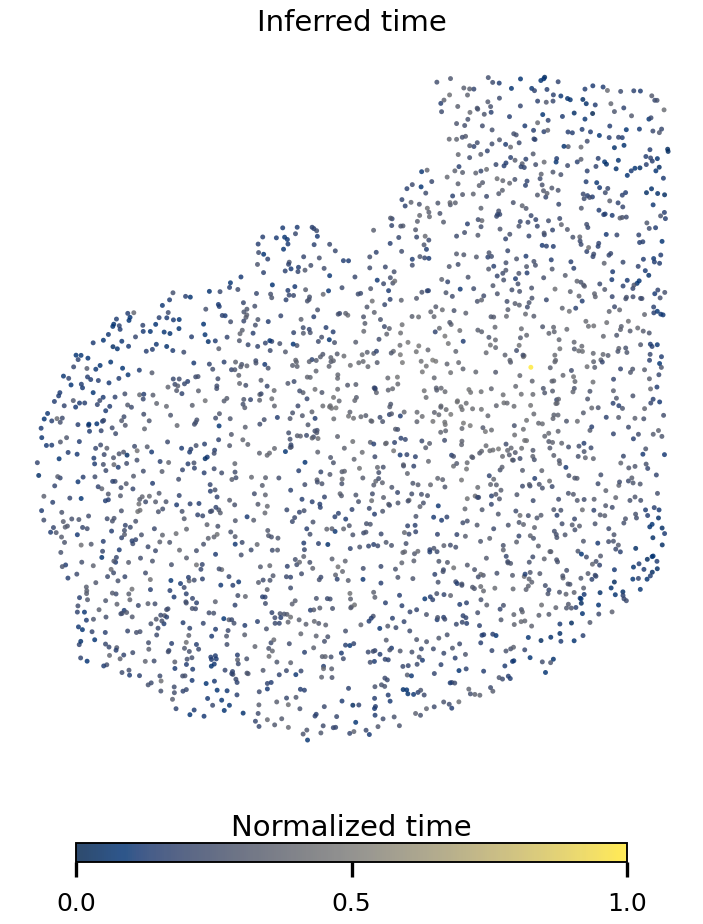
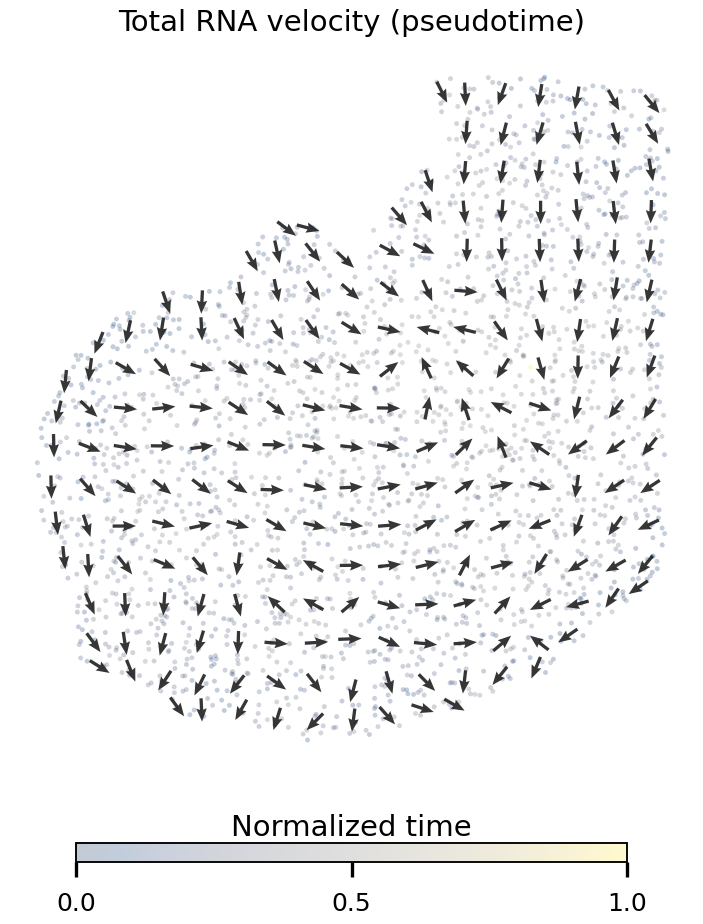
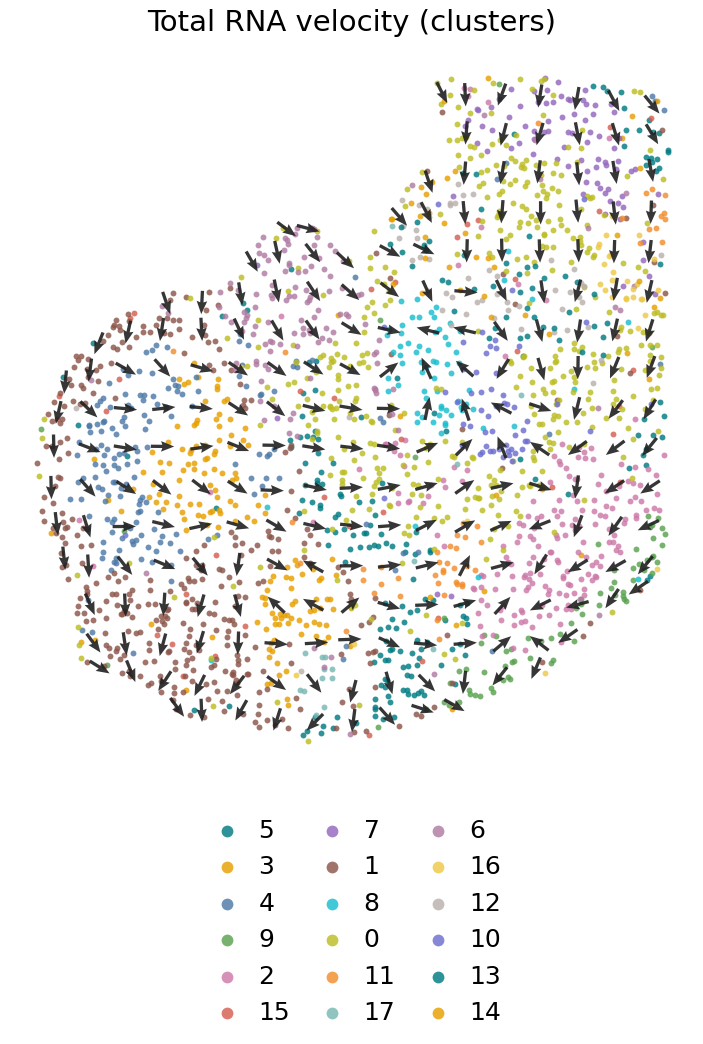

In [4]:
analysis = CellVOCALAnalysis.from_h5ad(cfg.eval.output_dir / "out.h5ad", config=cfg)
ccc = analysis.adata.uns["cv_ccc"]
section_overview = pd.DataFrame({"value": [
    str(analysis.adata.obs["sample"].iloc[0]), str(analysis.adata.obs["development_stage"].iloc[0]),
    f"{analysis.adata.n_obs:,}", f"{analysis.adata.n_vars:,}", f'{len(ccc["event_influence"]):,}'
]}, index=["sample", "developmental stage", "spots", "genes", "candidate CCC events"])
receiver = np.asarray(ccc["receiver"], dtype=int)
receiver_type = analysis.adata.obs.iloc[receiver]["cell_major_type"].astype(str).to_numpy()
receiver_summary = (
    pd.DataFrame({"cell population": receiver_type, "event_influence": np.clip(np.asarray(ccc["event_influence"], dtype=float), 0, None)})
    .groupby("cell population").agg(received_influence=("event_influence", "sum"), candidate_events=("event_influence", "size"))
    .sort_values("received_influence", ascending=False)
)
receiver_summary["event_influence share (%)"] = 100 * receiver_summary["received_influence"] / receiver_summary["received_influence"].sum()
display(section_overview, receiver_summary.head(8).round({"received_influence": 1, "event_influence share (%)": 1}))

with capture_output():
    velocity_plots = analysis.plot_velocity(output_dir=DATA_ROOT / "cellvocal" / SAMPLE / "velocity")
image_tiles = []
for path in velocity_plots:
    encoded = b64encode(Path(path).read_bytes()).decode("ascii")
    image_tiles.append(f'<img src="data:image/png;base64,{encoded}" alt="{Path(path).stem}" style="flex:1 1 0;min-width:0;width:32%;height:auto;object-fit:contain">')
display(HTML(f'<div style="font-weight:600;margin:4px 0">{SAMPLE}</div><div style="display:flex;flex-wrap:nowrap;gap:8px;align-items:flex-start;width:100%">' + "".join(image_tiles) + "</div>"))

## Rank communication programs

Summed positive influence ranks LR programs, and the added share column makes their concentration within this section explicit.

In [5]:
ccc = analysis.adata.uns["cv_ccc"]
module_index = np.asarray(ccc["module"], dtype=int)
valid = (module_index >= 0) & (module_index < len(ccc["lr_pairs"]))
lr_total_influence = pd.DataFrame({"LR module": np.asarray(ccc["lr_pairs"], dtype=str)[module_index[valid]], "event_influence": np.asarray(ccc["event_influence"], dtype=float)[valid]}).query("event_influence > 0").groupby("LR module", as_index=False)["event_influence"].sum().sort_values("event_influence", ascending=False)
lr_total_influence["share (%)"] = 100 * lr_total_influence["event_influence"] / lr_total_influence["event_influence"].sum()
display(lr_total_influence.head(10).round({"event_influence": 1, "share (%)": 1}))

,LR module,event_influence,share (%)
21,Flrt2->Flrt2,2063.9,8.7
2,Cdh2->Cdh2,1927.9,8.1
35,Ncam1->Ncam1,1457.9,6.1
48,Ptn->Ncl,1158.7,4.9
49,Ptprm->Ptprm,666.1,2.8
3,Cdh4->Cdh4,657.0,2.8
12,Dlk1->Notch2,613.4,2.6
19,Flrt2->Adgrl2,485.4,2.0
70,Tenm3->Adgrl2,475.8,2.0
64,Slit2->Robo1,468.7,2.0


## Reuse communication analysis tools

The following examples use `pipeline.analysis.CellVOCALAnalysis`.
Calculations live in `utils/tools` and plots in `utils/viz`.
The three levels resolve a receiver's gene response, locate its
spatial sender catchment, and summarize source–section–state input
allocation. Capture spots are the observation units; input influence
and signed RNA velocity remain distinct.

In [6]:
from IPython import get_ipython
from matplotlib_inline.backend_inline import set_matplotlib_formats

get_ipython().run_line_magic("matplotlib", "inline")
set_matplotlib_formats("retina")
import matplotlib.pyplot as plt

## Define receivers and the cycling-marker readout

The receiver population, signature and focal input are specified before
examining response directions. Expression and all velocity components use
the same gene-specific input SD; the original signature denominator is
retained if a gene is unavailable. The coverage table makes this explicit.
These examples use SDs from the selected section and illustrate the reusable
tools, rather than reproducing cross-section publication scaling.

In [7]:
a = analysis.adata
receiver_mask = a.obs["cell_major_type"].isin(["Immature inhibitory neuron", "Immature excitatory neuron"])
source_labels = a.obs["cell_major_type"]
FOCUS = 'Ncam1->Ncam1'
PROGRAM_GENES = ['Mki67', 'Top2a']
MARKER_GENES = ['Mki67', 'Top2a', 'Dcx', 'Tubb3', 'Map2']
scale_genes = [g for g in dict.fromkeys(PROGRAM_GENES + MARKER_GENES) if g in a.var_names]
columns = a.var_names.get_indexer(scale_genes)
x = a.layers["spliced"][receiver_mask.to_numpy()][:, columns]
x = x.toarray() if hasattr(x, "toarray") else np.asarray(x)
sd = x.std(axis=0)
floor = max(float(np.median(sd[sd > 0])) * 0.01, 1e-6) if np.any(sd > 0) else 1e-6
gene_scale = pd.Series(np.maximum(sd, floor), index=scale_genes)
scores = analysis.program_scores(PROGRAM_GENES, gene_scale=gene_scale, missing="omit")
incoming = analysis.incoming_influence()
display(pd.DataFrame({"gene": PROGRAM_GENES,
                      "available": [g in a.var_names for g in PROGRAM_GENES]}))

,gene,available
0,Mki67,True
1,Top2a,True


## Screen candidate inputs against the cycling response

This B-style screen uses the negative communication-associated
Mki67/Top2a velocity, standardized among the selected receivers.
It nominates inputs; the subsequent spatial and statistical examples
use total velocity. High input is the upper quartile of positive
inputs and background is every other receiver. Bubble area represents
summed incoming influence. For several sections, concatenate
aligned receiver tables and pass `sections=` to give sections equal weight.

,module,n_sections,n_valid_rho_sections,n_valid_contrast_sections,mean_rho,mean_high_delta,total_influence,n_receivers,n_observations,min_active_receivers,positive_rho_sections,positive_contrast_sections
35,Ncam1->Ncam1,1,1,1,0.353845,1.060325,1242.751146,15671,15671,2881,1,1
68,Tenm2->Adgrl3,1,1,1,0.204253,1.734732,481.857832,15671,15671,744,1,1
74,Tenm4->Adgrl3,1,1,1,0.187443,1.348577,426.557501,15671,15671,603,1,1
62,Slc1a3->Grik2,1,1,1,0.185328,1.577372,336.257752,15671,15671,561,1,1
41,Nrxn1->Clstn1,1,1,1,0.184063,0.901288,286.610554,15671,15671,926,1,1
36,Ncam1->Ncam2,1,1,1,0.160349,0.779996,343.928561,15671,15671,707,1,1
37,Negr1->Negr1,1,1,1,0.156280,0.559706,980.771554,15671,15671,2075,1,1
17,Efna5->Ephb2,1,1,1,0.156125,1.157866,264.461190,15671,15671,511,1,1


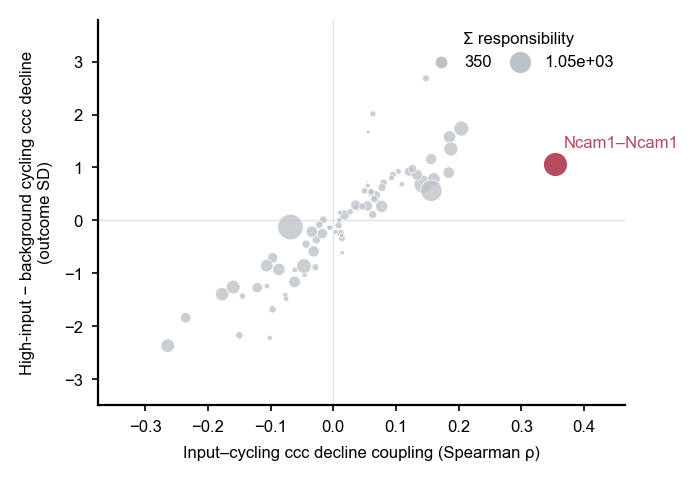

In [8]:
screening_scores = analysis.program_scores(["Mki67", "Top2a"])
per_section, screening = analysis.screen_communication(
    -screening_scores["ccc_velocity"], incoming=incoming,
    receiver_mask=receiver_mask, min_active=4, standardize_outcome=True,
    sections=np.repeat(SAMPLE, a.n_obs),
)
fig, ax = analysis.plot_communication_screen(
    screening, highlights={FOCUS: "#B64B5D"},
    outcome_label="Cycling CCC decline", outcome_units="outcome SD",
)
display(screening.sort_values("mean_rho", ascending=False).head(8), fig)
plt.close(fig)

## Point level: resolve one receiver's gene response

Select the receiver with greatest focal input, without using its response
sign. The checkpoint supplies the fixed response basis and mixing gate;
no training is performed. Sender contributions must reconstruct each
module response, and their sum must agree with saved communication
velocity. The ledger retains all modules, grouping those not highlighted.
Total and intrinsic velocities remain separately available in the table.

,receiver,receiver_id,gene,gene_scale,ccc_velocity_reconstructed,ccc_velocity_saved,total_velocity,intrinsic_velocity
0,30530,GSM9421073_GCCTTGACACAG,Mki67,0.742701,-0.278728,-0.278728,-0.047145,0.231583
1,30530,GSM9421073_GCCTTGACACAG,Top2a,0.679893,-0.444585,-0.444586,-0.304501,0.140085
2,30530,GSM9421073_GCCTTGACACAG,Dcx,0.318019,0.224029,0.224029,0.247747,0.023717
3,30530,GSM9421073_GCCTTGACACAG,Tubb3,0.379564,0.122174,0.122175,0.194311,0.072136
4,30530,GSM9421073_GCCTTGACACAG,Map2,0.358104,0.201335,0.201335,0.283314,0.081979


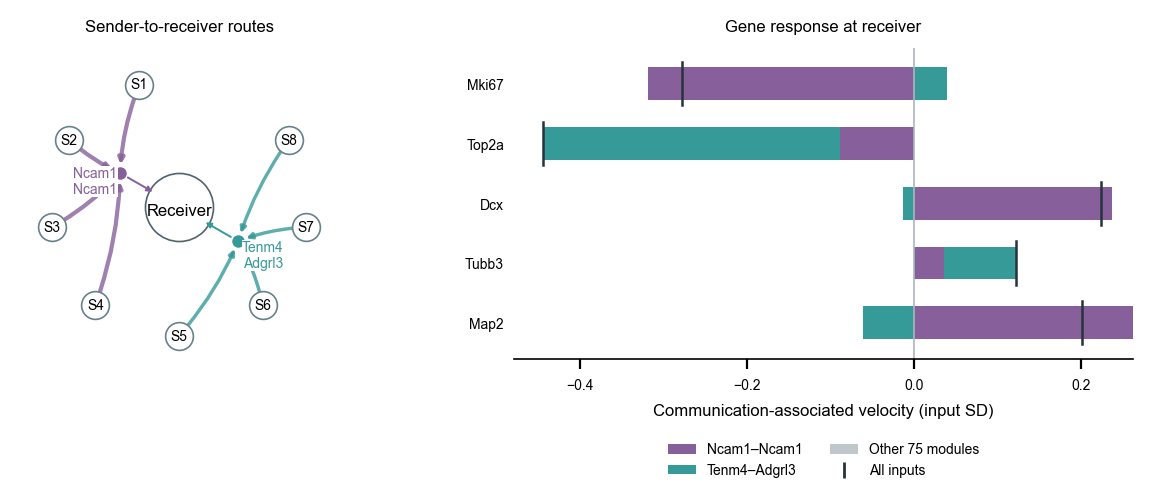

In [9]:
eligible = receiver_mask & incoming[FOCUS].gt(0)
if not eligible.any():
    raise ValueError("The selected section has no focal-input receivers.")
receiver_id = incoming.loc[eligible, FOCUS].idxmax()
receiver_index = int(a.obs_names.get_loc(receiver_id))
components = analysis.response_components()
marker_genes = [g for g in MARKER_GENES if g in a.var_names]
point = analysis.receiver_response(
    receiver_id, genes=marker_genes, gene_scale=gene_scale, components=components,
)
positive = incoming.loc[receiver_id].sort_values(ascending=False)
displayed_modules = [FOCUS] + [m for m in positive[positive > 0].index if m != FOCUS][:2]
fig, axes = analysis.plot_receiver_response(point, modules=displayed_modules)
display(point["gene_summary"], fig)
plt.close(fig)

## Tissue level: locate sender catchments and receiver dynamics

Routes remain in tissue coordinates. Receiver fill shows measured
signature expression and ring colour shows signed total velocity.
Width represents the magnitude of the attributed response across genes,
while source shares are computed from nonnegative influence.
All source classes and routes are retained in the tables. The inset is
centred on the same receiver as the point-level ledger; route selection
uses spatial position and input magnitude, never velocity sign.

,module_name,source_label,event_influence,n_events,n_senders,n_receivers,response_rms,programme_contribution,influence_fraction
0,Ncam1->Ncam1,Immature excitatory neuron,321.018646,2740,576,1649,15.918546,-64.871685,0.258313
1,Ncam1->Ncam1,Immature inhibitory neuron,761.226136,6868,1566,2659,37.610324,-153.270595,0.612533
2,Ncam1->Ncam1,Excitatory neuron,24.662851,232,76,193,1.214245,-4.948325,0.019845
3,Ncam1->Ncam1,Inhibitory neuron,16.021448,121,30,114,0.759735,-3.096093,0.012892
4,Ncam1->Ncam1,OPC/Oligodendrocyte,13.552115,141,67,134,0.656357,-2.674803,0.010905
5,Ncam1->Ncam1,Vascular,89.832015,1013,591,519,4.338376,-17.679866,0.072285
6,Ncam1->Ncam1,OEC,3.256173,32,12,32,0.156439,-0.637524,0.002620
7,Ncam1->Ncam1,Astro/Ependymal,13.126734,153,58,132,0.630584,-2.569772,0.010563
8,Ncam1->Ncam1,Monoaminergic neuron,0.055037,1,1,1,0.002774,-0.011305,0.000044


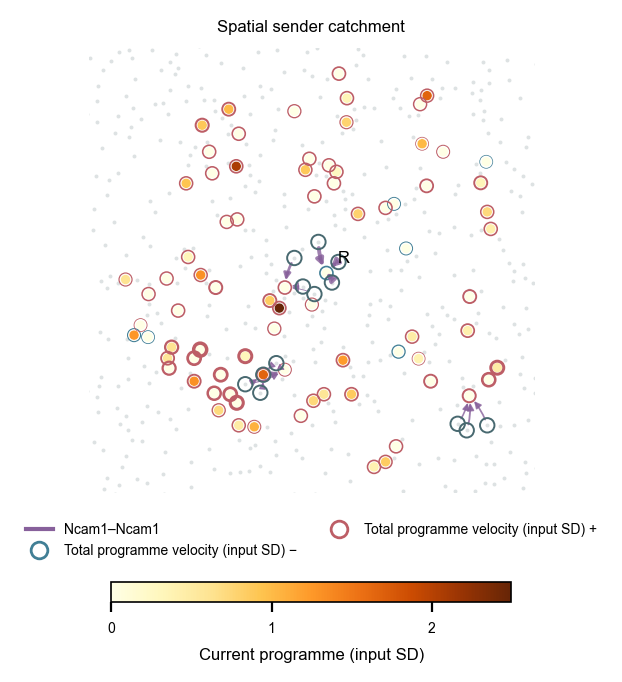

In [10]:
gene_weights = pd.Series(0.0, index=a.var_names)
available = scores.attrs["genes_available"]
gene_weights.loc[available] = 1 / (len(PROGRAM_GENES) * gene_scale.loc[available])
tissue = analysis.tissue_communication(
    modules=[FOCUS], receiver_mask=receiver_mask, source_labels=source_labels,
    observed_values=scores["current_expression"],
    velocity_values=scores["total_velocity"],
    observed_label="Current programme (input SD)",
    velocity_label="Total programme velocity (input SD)",
    gene_weights=gene_weights, **components,
)
xy = np.asarray(a.obsm["spatial"])[:, :2]
receiver_distance = np.linalg.norm(xy[receiver_mask.to_numpy()] - xy[receiver_index], axis=1)
# A comparable local view of about 80 receivers, chosen using position only.
radius = float(np.sort(receiver_distance)[min(80, len(receiver_distance) - 1)])
fig, ax = analysis.plot_sender_catchment(
    tissue, focus_receiver=receiver_index, radius=radius,
    max_receivers=10, max_routes_per_receiver=3,
)
display(tissue["source_summary"], fig)
plt.close(fig)

## Summary level: source → section → receiver lineage

NCAM1 input is summarized across E12.5, E14.5 and E15.5 using a Sankey
diagram. Each event contributes its input influence divided by the
number of immature neuronal receivers and by three, giving sections
equal weight. All sources are retained, with other sender classes grouped
together. Both sides of the diagram conserve the same input total.

The receiver groups are the annotated immature inhibitory and excitatory
neurons. The numerical codes below only represent these categories, with
an explicit boundary between them; they are not a continuous state score
or a temporal ordering. This avoids dividing sparse two-gene expression
measurements into degenerate quantile bins. The diagram summarizes input
allocation, not signed velocity or developmental transitions.


,section,n_receivers,section_weight,weighted_influence
0,GSM9421073,15671,0.333333,0.026434
1,GSM9421074,27199,0.333333,0.018421
2,GSM9421075,14895,0.333333,0.047348


,quantile,value,method
0,0.5,0.5,caller-supplied thresholds


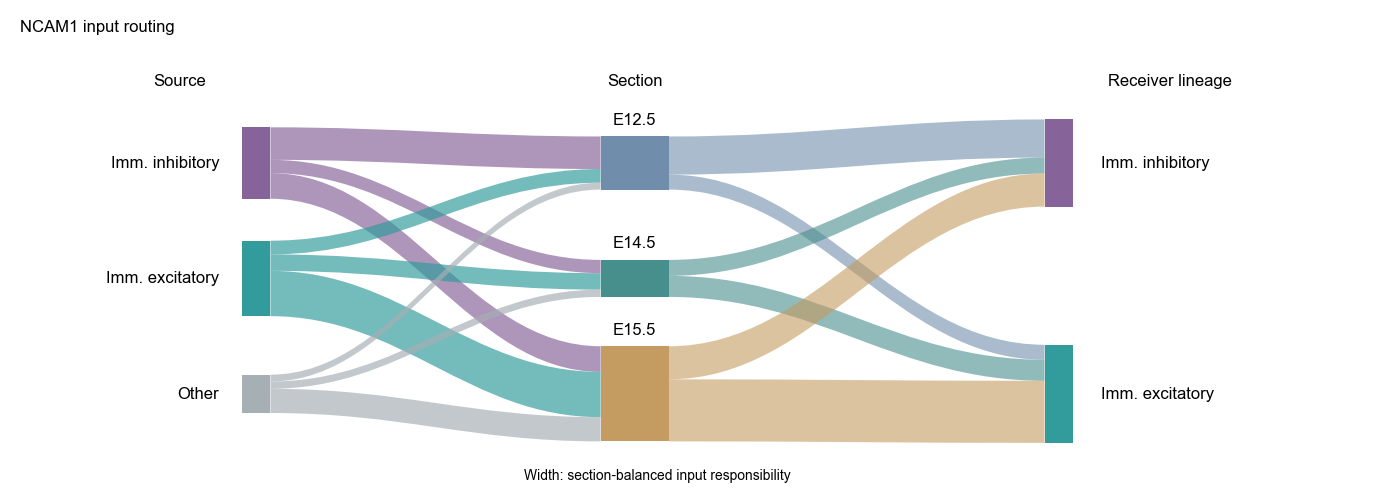

In [11]:
ROUTING_SAMPLES = ["GSM9421073", "GSM9421074", "GSM9421075"]

import h5py
from anndata.io import read_elem

routing_sections = {}
for section in ROUTING_SAMPLES:
    path = DATA_ROOT / "cellvocal" / section / "results" / "out.h5ad"
    with h5py.File(path, "r") as handle:
        obs = read_elem(handle["obs"])
        group = handle["uns/cv_ccc"]
        keys = ("sender", "receiver", "module", "lr_pairs", "event_influence",
                "module_activation_prob", "sender_share")
        routing_sections[section] = ad.AnnData(obs=obs, uns={"cv_ccc": {
            key: read_elem(group[key]) for key in keys if key in group
        }})

routing_masks = {s: value.obs["cell_major_type"].isin(
    ["Immature inhibitory neuron", "Immature excitatory neuron"]).to_numpy()
    for s, value in routing_sections.items()}

# Encode existing receiver annotations, without estimating state thresholds.
lineage_codes = {"Immature inhibitory neuron": 0., "Immature excitatory neuron": 1.}
for section in ROUTING_SAMPLES:
    routing_sections[section].obs["routing_lineage"] = (
        routing_sections[section].obs["cell_major_type"].astype(str)
        .map(lineage_codes).fillna(-1.)
    )

statistics = analysis.communication_statistics(
    FOCUS, sections=routing_sections, receiver_masks=routing_masks,
    source_labels="cell_major_type", state_values="routing_lineage", weighting="section",
    state_labels=("Immature inhibitory", "Immature excitatory"),
    quantiles=(.5,), state_thresholds=(.5,),
    source_groups={"Immature inhibitory neuron": "Immature inhibitory",
                   "Immature excitatory neuron": "Immature excitatory"},
    source_order=["Immature inhibitory", "Immature excitatory", "Other"],
)
fig, ax = analysis.plot_communication_statistics(
    statistics, state_title="Receiver lineage", title="NCAM1 input routing",
    source_labels={"Immature inhibitory": "Imm. inhibitory", "Immature excitatory": "Imm. excitatory"},
    section_labels=dict(zip(ROUTING_SAMPLES, ["E12.5", "E14.5", "E15.5"])),
    source_colors={"Immature inhibitory": "#86649A", "Immature excitatory": "#329B9C"},
    state_labels={"Immature inhibitory": "Imm. inhibitory", "Immature excitatory": "Imm. excitatory"},
    state_colors={"Immature inhibitory": "#86649A", "Immature excitatory": "#329B9C"},
)

display(statistics["sections"][["section", "n_receivers", "section_weight", "weighted_influence"]],
        statistics["thresholds"], fig)
plt.close(fig)
# Direct plotting data: one row per source, section, state and selected module.
# statistics["flow"].to_csv("input_routing.csv", index=False)
